# Digital Twin & Simulation Engine Prototype

**Project:** Omni-Grid Renewable Energy Intelligence Platform  
**Notebook purpose:** Build a prototype Digital Twin & Simulation Engine using the provided synthetic inverter dataset.

This notebook implements:

1. **Component-Level Digital Twin** – predicts inverter electrical and thermal behaviour from asset, environmental, operating, and health-state variables.
2. **Plant-Level Simulation** – aggregates component-level predictions into plant-level operational KPIs.
3. **What-if Scenario Simulation** – tests heatwave, soiling, power-quality disturbance, preventive-maintenance, and combined-stress scenarios.
4. **Synthetic Failure Injection** – flags simulated thermal, power-quality, insulation, and control/communication stress patterns.
5. **Prototype Export** – saves trained model, metrics, scenario outputs, and metadata.

The approach follows the PRD direction for **Component 8: Digital Twin & Simulation Engine**, where the goal is to create virtual replicas of renewable assets for scenario testing, RL-agent training, and what-if analysis.

## 1. Prototype Scope

The PRD requires two Digital Twin modules:

| PRD Module | Prototype Implementation |
|---|---|
| **Model 8A: Component-Level Digital Twins** | Train ML models that simulate inverter efficiency, internal temperature, reactive power capability, voltage ripple, harmonic distortion, insulation resistance, and fan speed. |
| **Model 8B: Plant-Level Simulation** | Aggregate inverter-level predictions into plant-level energy, thermal risk, power-quality risk, and high-risk asset counts. |

This is a **hybrid physics-informed ML prototype**:

- Physics-inspired features represent load, thermal stress, ageing, dust/soiling exposure, and cumulative operational stress.
- Machine learning learns the residual patterns from telemetry.
- Scenario functions modify external/controllable drivers and pass the new state through the digital twin.

In [1]:
# ============================================
# 2. Imports and global settings
# ============================================

import json
import math
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# ================================================================
# Data paths (portable)
# ================================================================
# Run this notebook from its own module folder. Data lives in ./data.
# If the full synthetic dataset is not present, the sample file is used
# so the notebook still runs end to end for anyone who clones the repo.

DATA_DIR = Path.cwd() / "data"
DATASET_PATH = DATA_DIR / "synthetic_digital_twin_dataset.csv"
SAMPLE_PATH = DATA_DIR / "synthetic_digital_twin_sample.csv"
DICTIONARY_PATH = DATA_DIR / "synthetic_digital_twin_data_dictionary.csv"

if not DATASET_PATH.exists():
    print(f"Full dataset not found, using sample file: {SAMPLE_PATH.name}")
    DATASET_PATH = SAMPLE_PATH

OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
print("Dataset path:", DATASET_PATH)


In [3]:
# ============================================
# 4. Load dataset and dictionary
# ============================================

df = pd.read_csv(DATASET_PATH)
dictionary_df = pd.read_csv(DICTIONARY_PATH)

print("Dataset shape:", df.shape)
print("Dictionary shape:", dictionary_df.shape)

display(df.head())
display(dictionary_df.head(10))

Dataset shape: (32627, 42)
Dictionary shape: (42, 2)


,date,inverter_id,manufacturer,climate_zone,rated_capacity_kw,installation_quality_score,maintenance_quality_score,age_months,ambient_temperature_c,humidity_pct,dust_soiling_index,uv_exposure_index,cumulative_uv_exposure,operating_hours_today,cumulative_operating_hours,cumulative_energy_throughput_mwh,efficiency_pct,reactive_power_capability,internal_temperature_c,voltage_ripple,current_harmonic_distortion_pct,insulation_resistance_mohm,capacitor_degradation_indicator,fan_speed_rpm,restart_count_today,error_code_count_today,thermal_cycling_count_today,overload_events_today,failure_within_7d,failure_within_30d,failure_within_90d,rul_days,failed_today,is_censored,efficiency_7d_mean,efficiency_30d_mean,temperature_7d_mean,temperature_30d_mean,efficiency_decline_7d,temp_stress_index,restart_7d_sum,errors_7d_sum
0,2025-01-01,INV-0001,Fronius,Temperate,100,0.789,0.88,83.00,19.57,40.05,0.292,6.43,6.43,11.78,11.78,1.161,97.93,1.057,28.51,2.631,5.431,79.04,0.427,2676.3,0,0,3,0,0,0,0,127.0,0,0,97.9300,97.9300,28.510000,28.510000,0.0000,0.0,0.0,0.0
1,2025-01-02,INV-0001,Fronius,Temperate,100,0.789,0.88,83.03,23.48,41.48,0.346,6.33,12.76,12.30,24.08,2.112,97.46,1.076,36.64,2.569,5.509,77.96,0.383,2573.1,0,0,0,0,0,0,0,126.0,0,0,97.6950,97.6950,32.575000,32.575000,-0.2350,0.0,0.0,0.0
2,2025-01-03,INV-0001,Fronius,Temperate,100,0.789,0.88,83.07,21.69,45.80,0.329,7.88,20.64,12.34,36.42,2.967,98.04,0.958,32.22,3.072,5.553,80.58,0.295,2865.0,0,0,0,0,0,0,0,125.0,0,0,97.8100,97.8100,32.456667,32.456667,0.2300,0.0,0.0,0.0
3,2025-01-04,INV-0001,Fronius,Temperate,100,0.789,0.88,83.10,21.43,22.49,0.186,7.09,27.74,10.41,46.83,3.794,97.48,1.039,35.10,2.268,5.643,76.89,0.502,2451.1,0,0,4,1,0,0,0,124.0,0,0,97.7275,97.7275,33.117500,33.117500,-0.2475,0.0,0.0,0.0
4,2025-01-05,INV-0001,Fronius,Temperate,100,0.789,0.88,83.13,23.25,33.41,0.368,6.04,33.78,14.66,61.49,5.075,98.43,0.926,36.49,2.869,5.472,82.03,0.367,2605.3,0,0,0,0,0,0,0,123.0,0,0,97.8680,97.8680,33.792000,33.792000,0.5620,0.0,0.0,0.0


,column_name,description
0,date,Observation date
1,inverter_id,Unique inverter identifier
2,manufacturer,Inverter manufacturer
3,climate_zone,Synthetic site climate classification
4,rated_capacity_kw,Rated inverter capacity in kW
5,installation_quality_score,Synthetic installation quality score
6,maintenance_quality_score,Synthetic maintenance quality score
7,age_months,Age of inverter in months
8,ambient_temperature_c,Ambient temperature in Celsius
9,humidity_pct,Humidity percentage


In [4]:
# ============================================
# 5. Basic data audit
# ============================================

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["inverter_id", "date"]).reset_index(drop=True)

summary = {
    "rows": len(df),
    "columns": df.shape[1],
    "date_min": str(df["date"].min().date()),
    "date_max": str(df["date"].max().date()),
    "unique_inverters": int(df["inverter_id"].nunique()),
    "manufacturers": df["manufacturer"].nunique(),
    "climate_zones": df["climate_zone"].nunique(),
    "failure_within_7d_positive": int(df["failure_within_7d"].sum()),
    "failure_within_30d_positive": int(df["failure_within_30d"].sum()),
    "failure_within_90d_positive": int(df["failure_within_90d"].sum()),
    "failed_today_positive": int(df["failed_today"].sum()),
    "censored_rul_rows": int(df["is_censored"].sum()),
}

print(json.dumps(summary, indent=2))

missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print("\nMissing values:")
display(missing.to_frame("missing_count"))

print("\nManufacturer distribution:")
display(df["manufacturer"].value_counts().to_frame("records"))

print("\nClimate zone distribution:")
display(df["climate_zone"].value_counts().to_frame("records"))

{
  "rows": 32627,
  "columns": 42,
  "date_min": "2025-01-01",
  "date_max": "2025-12-31",
  "unique_inverters": 120,
  "manufacturers": 4,
  "climate_zones": 4,
  "failure_within_7d_positive": 583,
  "failure_within_30d_positive": 2262,
  "failure_within_90d_positive": 6488,
  "failed_today_positive": 72,
  "censored_rul_rows": 17155
}

Missing values:


,missing_count
rul_days,17155



Manufacturer distribution:


,records
manufacturer,
SMA,13334
Fronius,8858
Huawei,5254
SolarEdge,5181



Climate zone distribution:


,records
climate_zone,
Coastal,10122
Temperate,8632
Hot-Dry,8572
Humid-Subtropical,5301


## 6. Digital Twin Target Variables

The digital twin is trained to simulate key **electrical and thermal behaviours** of each inverter.

| Target | Why it matters |
|---|---|
| `efficiency_pct` | Conversion performance and degradation. |
| `internal_temperature_c` | Thermal stress and cooling behaviour. |
| `reactive_power_capability` | Grid-support capability. |
| `voltage_ripple` | DC-link/electrical instability. |
| `current_harmonic_distortion_pct` | Power-quality distortion. |
| `insulation_resistance_mohm` | Safety and degradation indicator. |
| `fan_speed_rpm` | Cooling system response. |

Current target values are excluded from the input matrix. Lagged previous-day values are used as system-state memory.

In [5]:
# ============================================
# 7. Feature engineering for digital twin modelling
# ============================================

TARGET_COLUMNS = [
    "efficiency_pct",
    "internal_temperature_c",
    "reactive_power_capability",
    "voltage_ripple",
    "current_harmonic_distortion_pct",
    "insulation_resistance_mohm",
    "fan_speed_rpm",
]

LABEL_AND_OUTCOME_COLUMNS = [
    "failure_within_7d",
    "failure_within_30d",
    "failure_within_90d",
    "rul_days",
    "failed_today",
    "is_censored",
]

ROLLING_STATE_COLUMNS = [
    "efficiency_7d_mean",
    "efficiency_30d_mean",
    "temperature_7d_mean",
    "temperature_30d_mean",
    "restart_7d_sum",
    "errors_7d_sum",
]


def add_digital_twin_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data["date"] = pd.to_datetime(data["date"])
    data = data.sort_values(["inverter_id", "date"]).reset_index(drop=True)

    # Calendar state
    data["month"] = data["date"].dt.month
    data["day_of_year"] = data["date"].dt.dayofyear
    data["week_of_year"] = data["date"].dt.isocalendar().week.astype(int)
    data["season_sin"] = np.sin(2 * np.pi * data["day_of_year"] / 365.25)
    data["season_cos"] = np.cos(2 * np.pi * data["day_of_year"] / 365.25)

    # Lag rolling state variables and previous target behaviour by inverter.
    for col in ROLLING_STATE_COLUMNS:
        data[f"{col}_lag1"] = data.groupby("inverter_id")[col].shift(1)
    for col in TARGET_COLUMNS:
        data[f"{col}_lag1"] = data.groupby("inverter_id")[col].shift(1)

    # Physics-inspired stress variables
    data["age_years"] = data["age_months"] / 12
    data["load_factor_proxy"] = (data["operating_hours_today"] / 15).clip(0, 1.25)
    data["thermal_margin_c"] = data["internal_temperature_c_lag1"] - data["ambient_temperature_c"]
    data["positive_heat_exposure_c"] = (data["ambient_temperature_c"] - 25).clip(lower=0)
    data["soiling_stress"] = data["dust_soiling_index"] * data["operating_hours_today"]
    data["uv_stress"] = data["uv_exposure_index"] * data["operating_hours_today"]
    data["quality_score_mean"] = (
        data["installation_quality_score"] + data["maintenance_quality_score"]
    ) / 2
    data["cumulative_stress_proxy"] = (
        0.35 * data["age_years"]
        + 0.30 * data["cumulative_energy_throughput_mwh"] / data["cumulative_energy_throughput_mwh"].max()
        + 0.20 * data["cumulative_uv_exposure"] / data["cumulative_uv_exposure"].max()
        + 0.15 * data["dust_soiling_index"]
    )

    # Event pressure features
    data["event_pressure_score"] = (
        data["restart_count_today"]
        + data["error_code_count_today"]
        + 1.5 * data["overload_events_today"]
        + 0.5 * data["thermal_cycling_count_today"]
    )
    data["rolling_event_pressure_lag1"] = (
        data["restart_7d_sum_lag1"].fillna(0) + data["errors_7d_sum_lag1"].fillna(0)
    )

    return data

model_df = add_digital_twin_features(df)
model_df = model_df.dropna(subset=["efficiency_pct_lag1", "internal_temperature_c_lag1"]).reset_index(drop=True)

print("Feature-engineered dataset shape:", model_df.shape)
display(model_df.head())

Feature-engineered dataset shape: (32507, 70)


,date,inverter_id,manufacturer,climate_zone,rated_capacity_kw,installation_quality_score,maintenance_quality_score,age_months,ambient_temperature_c,humidity_pct,dust_soiling_index,uv_exposure_index,cumulative_uv_exposure,operating_hours_today,cumulative_operating_hours,cumulative_energy_throughput_mwh,efficiency_pct,reactive_power_capability,internal_temperature_c,voltage_ripple,current_harmonic_distortion_pct,insulation_resistance_mohm,capacitor_degradation_indicator,fan_speed_rpm,restart_count_today,error_code_count_today,thermal_cycling_count_today,overload_events_today,failure_within_7d,failure_within_30d,failure_within_90d,rul_days,failed_today,is_censored,efficiency_7d_mean,efficiency_30d_mean,temperature_7d_mean,temperature_30d_mean,efficiency_decline_7d,temp_stress_index,restart_7d_sum,errors_7d_sum,month,day_of_year,week_of_year,season_sin,season_cos,efficiency_7d_mean_lag1,efficiency_30d_mean_lag1,temperature_7d_mean_lag1,temperature_30d_mean_lag1,restart_7d_sum_lag1,errors_7d_sum_lag1,efficiency_pct_lag1,internal_temperature_c_lag1,reactive_power_capability_lag1,voltage_ripple_lag1,current_harmonic_distortion_pct_lag1,insulation_resistance_mohm_lag1,fan_speed_rpm_lag1,age_years,load_factor_proxy,thermal_margin_c,positive_heat_exposure_c,soiling_stress,uv_stress,quality_score_mean,cumulative_stress_proxy,event_pressure_score,rolling_event_pressure_lag1
0,2025-01-02,INV-0001,Fronius,Temperate,100,0.789,0.88,83.03,23.48,41.48,0.346,6.33,12.76,12.30,24.08,2.112,97.46,1.076,36.64,2.569,5.509,77.96,0.383,2573.1,0,0,0,0,0,0,0,126.0,0,0,97.6950,97.6950,32.575000,32.575000,-0.2350,0.0,0.0,0.0,1,2,1,0.034398,0.999408,97.9300,97.9300,28.510000,28.510000,0.0,0.0,97.93,28.51,1.057,2.631,5.431,79.04,2676.3,6.919167,0.820000,5.03,0.0,4.25580,77.8590,0.8345,2.475356,0.0,0.0
1,2025-01-03,INV-0001,Fronius,Temperate,100,0.789,0.88,83.07,21.69,45.80,0.329,7.88,20.64,12.34,36.42,2.967,98.04,0.958,32.22,3.072,5.553,80.58,0.295,2865.0,0,0,0,0,0,0,0,125.0,0,0,97.8100,97.8100,32.456667,32.456667,0.2300,0.0,0.0,0.0,1,3,1,0.051584,0.998669,97.6950,97.6950,32.575000,32.575000,0.0,0.0,97.46,36.64,1.076,2.569,5.509,77.96,2573.1,6.922500,0.822667,14.95,0.0,4.05986,97.2392,0.8345,2.474912,0.0,0.0
2,2025-01-04,INV-0001,Fronius,Temperate,100,0.789,0.88,83.10,21.43,22.49,0.186,7.09,27.74,10.41,46.83,3.794,97.48,1.039,35.10,2.268,5.643,76.89,0.502,2451.1,0,0,4,1,0,0,0,124.0,0,0,97.7275,97.7275,33.117500,33.117500,-0.2475,0.0,0.0,0.0,1,4,1,0.068755,0.997634,97.8100,97.8100,32.456667,32.456667,0.0,0.0,98.04,32.22,0.958,3.072,5.553,80.58,2865.0,6.925000,0.694000,10.79,0.0,1.93626,73.8069,0.8345,2.455201,3.5,0.0
3,2025-01-05,INV-0001,Fronius,Temperate,100,0.789,0.88,83.13,23.25,33.41,0.368,6.04,33.78,14.66,61.49,5.075,98.43,0.926,36.49,2.869,5.472,82.03,0.367,2605.3,0,0,0,0,0,0,0,123.0,0,0,97.8680,97.8680,33.792000,33.792000,0.5620,0.0,0.0,0.0,1,5,1,0.085906,0.996303,97.7275,97.7275,33.117500,33.117500,0.0,0.0,97.48,35.10,1.039,2.268,5.643,76.89,2451.1,6.927500,0.977333,11.85,0.0,5.39488,88.5464,0.8345,2.484291,0.0,0.0
4,2025-01-06,INV-0001,Fronius,Temperate,100,0.789,0.88,83.17,22.86,40.87,0.440,5.74,39.52,10.47,71.95,6.049,97.79,0.972,31.56,3.150,5.250,78.13,0.351,2563.4,0,0,1,1,0,0,0,122.0,0,0,97.8550,97.8550,33.420000,33.420000,-0.0650,0.0,0.0,0.0,1,6,2,0.103031,0.994678,97.8680,97.8680,33.792000,33.792000,0.0,0.0,98.43,36.49,0.926,2.869,5.472,82.03,2605.3,6.930833,0.698000,13.63,0.0,4.60680,60.0978,0.8345,2.497051,2.0,0.0


In [6]:
# ============================================
# 8. Define feature matrix and time-aware split
# ============================================

EXCLUDE_COLUMNS = ["date"] + TARGET_COLUMNS + LABEL_AND_OUTCOME_COLUMNS + ROLLING_STATE_COLUMNS
FEATURE_COLUMNS = [c for c in model_df.columns if c not in EXCLUDE_COLUMNS]

categorical_features = ["inverter_id", "manufacturer", "climate_zone"]
numeric_features = [c for c in FEATURE_COLUMNS if c not in categorical_features]

print("Number of features:", len(FEATURE_COLUMNS))
print("Categorical features:", categorical_features)
print("Number of numeric features:", len(numeric_features))

# Time-aware split: train on earlier observations, test on later observations.
cutoff_date = model_df["date"].quantile(0.80)
train_df = model_df[model_df["date"] <= cutoff_date].copy()
test_df = model_df[model_df["date"] > cutoff_date].copy()

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET_COLUMNS]
X_test = test_df[FEATURE_COLUMNS]
y_test = test_df[TARGET_COLUMNS]

print("Cutoff date:", cutoff_date.date())
print("Training shape:", X_train.shape, y_train.shape)
print("Testing shape:", X_test.shape, y_test.shape)

Number of features: 50
Categorical features: ['inverter_id', 'manufacturer', 'climate_zone']
Number of numeric features: 47
Cutoff date: 2025-09-12
Training shape: (26046, 50) (26046, 7)
Testing shape: (6461, 50) (6461, 7)


In [7]:
# ============================================
# 9. Train Component-Level Digital Twin
# ============================================

# A single interpretable DecisionTreeRegressor is used for the prototype because:
# 1. it supports multi-output regression natively,
# 2. it runs quickly on a laptop,
# 3. it can model non-linear threshold behaviour,
# 4. its feature importances are easy to explain to operators.
#
# In a production version, this can be upgraded to ExtraTrees, LightGBM, XGBoost,
# or a physics-informed neural network after validation on real SCADA data.

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

component_twin_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=16,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
        )),
    ]
)

component_twin_model.fit(X_train, y_train)
print("Component-level digital twin model trained successfully.")

Component-level digital twin model trained successfully.


In [8]:
# ============================================
# 10. Model evaluation utilities
# ============================================


def safe_mape(y_true, y_pred, eps=1e-6):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = np.maximum(np.abs(y_true), eps)
    return np.mean(np.abs((y_true - y_pred) / denom)) * 100


def pct_within_tolerance(y_true, y_pred, tolerance_pct=3.0, eps=1e-6):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = np.maximum(np.abs(y_true), eps)
    pct_error = np.abs((y_true - y_pred) / denom) * 100
    return np.mean(pct_error <= tolerance_pct) * 100


def evaluate_multioutput_model(model, X, y, target_cols):
    preds = model.predict(X)
    metrics = []
    for i, target in enumerate(target_cols):
        y_true = y[target].values
        y_pred = preds[:, i]
        rmse = math.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)
        mape = safe_mape(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        within_3 = pct_within_tolerance(y_true, y_pred, tolerance_pct=3)
        metrics.append({
            "target": target,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE_%": mape,
            "R2": r2,
            "samples_within_3pct_%": within_3,
        })
    return pd.DataFrame(metrics), preds

metrics_df, test_predictions = evaluate_multioutput_model(component_twin_model, X_test, y_test, TARGET_COLUMNS)
metrics_df.to_csv(OUTPUT_DIR / "component_twin_metrics.csv", index=False)
display(metrics_df)

,target,MAE,RMSE,MAPE_%,R2,samples_within_3pct_%
0,efficiency_pct,0.446289,0.593871,0.463655,0.931671,99.907135
1,internal_temperature_c,4.215369,5.321941,12.196389,0.273975,16.607336
2,reactive_power_capability,0.041683,0.051836,4.313636,0.436246,42.114224
3,voltage_ripple,0.234774,0.295612,9.754204,0.879075,22.210184
4,current_harmonic_distortion_pct,0.484612,0.608464,10.080436,0.863110,21.235103
5,insulation_resistance_mohm,2.126364,2.703604,2.697952,0.886273,63.813651
6,fan_speed_rpm,249.214870,312.911369,9.728454,0.240747,20.058814


### Interpreting the Evaluation

For a digital twin, normal regression metrics are not enough. The PRD target is **simulation accuracy within 3% of real measurements**, so this notebook reports:

- **MAE:** average absolute error in the unit of the target.
- **RMSE:** penalises large errors.
- **MAPE:** average percentage error.
- **R²:** variance explained by the digital twin.
- **Samples within 3%:** percentage of test records where the simulated value is within 3% of the observed value.

For small-valued targets such as voltage ripple, MAPE can be stricter than for efficiency or temperature.

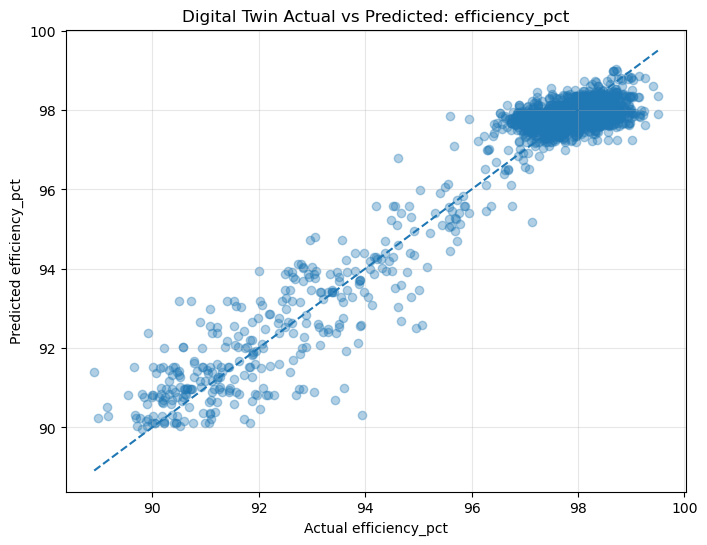

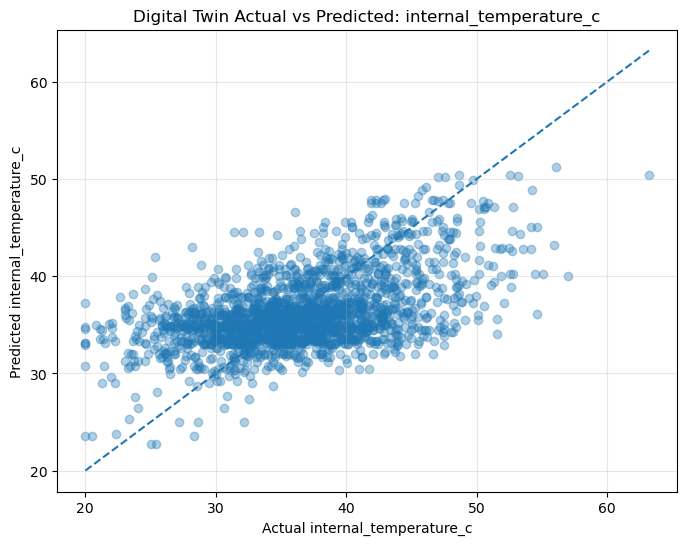

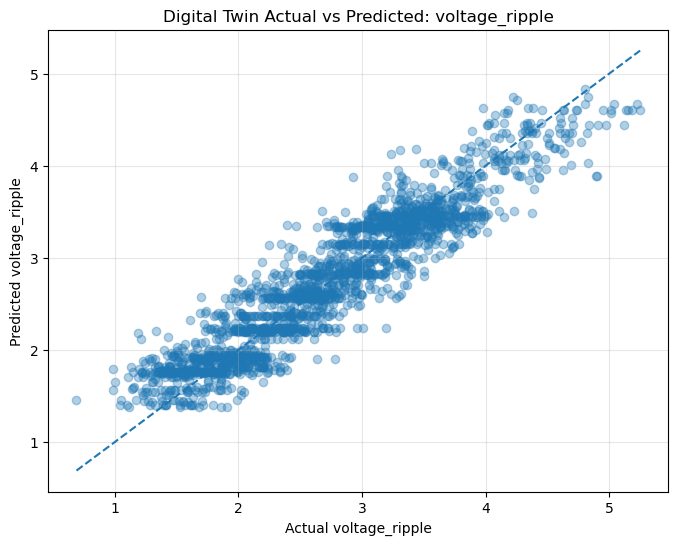

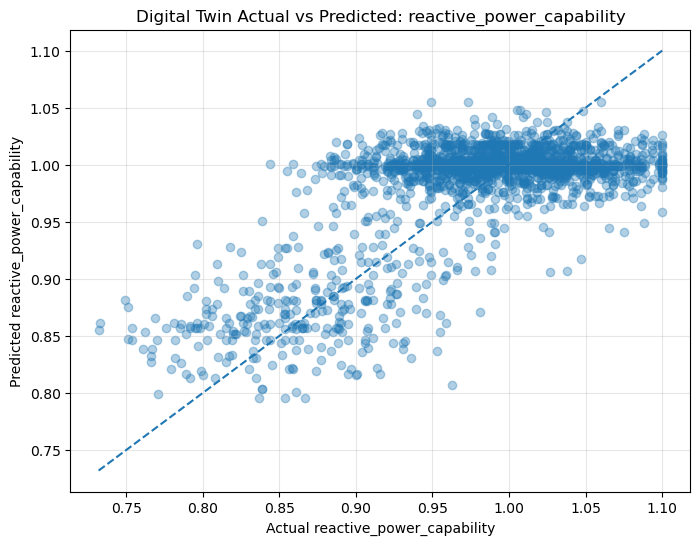

In [9]:
# ============================================
# 11. Actual vs Predicted plots
# ============================================

prediction_df = test_df[["date", "inverter_id", "manufacturer", "climate_zone", "rated_capacity_kw"]].copy()
for i, target in enumerate(TARGET_COLUMNS):
    prediction_df[f"actual_{target}"] = y_test[target].values
    prediction_df[f"predicted_{target}"] = test_predictions[:, i]
    prediction_df[f"residual_{target}"] = prediction_df[f"actual_{target}"] - prediction_df[f"predicted_{target}"]

prediction_df.to_csv(OUTPUT_DIR / "component_level_predictions.csv", index=False)

def plot_actual_vs_predicted(target, sample_size=2000):
    plot_df = prediction_df.sample(min(sample_size, len(prediction_df)), random_state=RANDOM_STATE)
    plt.figure(figsize=(8, 6))
    plt.scatter(plot_df[f"actual_{target}"], plot_df[f"predicted_{target}"], alpha=0.35)
    min_v = min(plot_df[f"actual_{target}"].min(), plot_df[f"predicted_{target}"].min())
    max_v = max(plot_df[f"actual_{target}"].max(), plot_df[f"predicted_{target}"].max())
    plt.plot([min_v, max_v], [min_v, max_v], linestyle="--")
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Digital Twin Actual vs Predicted: {target}")
    plt.grid(True, alpha=0.3)
    plt.show()

for target in ["efficiency_pct", "internal_temperature_c", "voltage_ripple", "reactive_power_capability"]:
    plot_actual_vs_predicted(target)

In [10]:
# ============================================
# 12. Plant-level aggregation from component predictions
# ============================================


def add_simulated_energy_and_risk(pred_df: pd.DataFrame) -> pd.DataFrame:
    out = pred_df.copy()

    # Temperature derating: simple inverter/PV-inspired penalty for heat above 25C.
    temp_derate = 1 - 0.004 * (out["predicted_internal_temperature_c"] - 25).clip(lower=0)
    temp_derate = temp_derate.clip(0.75, 1.05)

    if "dust_soiling_index" in out.columns:
        soiling_derate = (1 - 0.12 * out["dust_soiling_index"]).clip(0.80, 1.02)
    else:
        soiling_derate = 1.0

    reactive_factor = out["predicted_reactive_power_capability"].clip(0.70, 1.10)

    out["simulated_energy_mwh"] = (
        out["rated_capacity_kw"]
        * out["operating_hours_today"]
        * (out["predicted_efficiency_pct"] / 100)
        * temp_derate
        * soiling_derate
        * reactive_factor
        / 1000
    )

    # Rule-based digital twin stress score for scenario testing.
    temp_score = ((out["predicted_internal_temperature_c"] - 40) / 20).clip(0, 1)
    ripple_score = ((out["predicted_voltage_ripple"] - 3.2) / 2.5).clip(0, 1)
    harmonic_score = ((out["predicted_current_harmonic_distortion_pct"] - 6.5) / 4).clip(0, 1)
    insulation_score = ((75 - out["predicted_insulation_resistance_mohm"]) / 20).clip(0, 1)
    event_score = ((out["restart_count_today"] + out["error_code_count_today"] + out["overload_events_today"]) / 8).clip(0, 1)

    out["digital_twin_stress_score"] = (
        0.25 * temp_score
        + 0.20 * ripple_score
        + 0.20 * harmonic_score
        + 0.20 * insulation_score
        + 0.15 * event_score
    ).clip(0, 1)

    out["simulated_fault_class"] = np.select(
        [
            out["digital_twin_stress_score"] >= 0.75,
            out["digital_twin_stress_score"] >= 0.50,
            out["digital_twin_stress_score"] >= 0.30,
        ],
        ["CRITICAL_SIMULATED_FAULT", "HIGH_SIMULATED_RISK", "MODERATE_SIMULATED_RISK"],
        default="NORMAL_SIMULATED_STATE",
    )
    return out

simulation_base = test_df[[
    "date", "inverter_id", "manufacturer", "climate_zone", "rated_capacity_kw",
    "operating_hours_today", "dust_soiling_index", "restart_count_today", "error_code_count_today",
    "overload_events_today", "thermal_cycling_count_today"
]].copy()

for i, target in enumerate(TARGET_COLUMNS):
    simulation_base[f"predicted_{target}"] = test_predictions[:, i]

simulation_base = add_simulated_energy_and_risk(simulation_base)

plant_daily_simulation = (
    simulation_base.groupby("date")
    .agg(
        simulated_energy_mwh=("simulated_energy_mwh", "sum"),
        avg_predicted_efficiency_pct=("predicted_efficiency_pct", "mean"),
        avg_predicted_temperature_c=("predicted_internal_temperature_c", "mean"),
        avg_stress_score=("digital_twin_stress_score", "mean"),
        high_risk_assets=("digital_twin_stress_score", lambda x: int((x >= 0.5).sum())),
        critical_assets=("digital_twin_stress_score", lambda x: int((x >= 0.75).sum())),
        active_assets=("inverter_id", "nunique"),
    )
    .reset_index()
)

simulation_base.to_csv(OUTPUT_DIR / "component_level_simulation_base.csv", index=False)
plant_daily_simulation.to_csv(OUTPUT_DIR / "plant_daily_simulation_base.csv", index=False)

display(plant_daily_simulation.head())

,date,simulated_energy_mwh,avg_predicted_efficiency_pct,avg_predicted_temperature_c,avg_stress_score,high_risk_assets,critical_assets,active_assets
0,2025-09-13,83.496499,96.717342,36.375226,0.074772,0,0,71
1,2025-09-14,82.824493,96.602109,36.573564,0.072271,1,0,71
2,2025-09-15,82.738895,96.661411,36.542817,0.072620,1,0,70
3,2025-09-16,80.094839,96.737099,37.229172,0.073169,0,0,70
4,2025-09-17,80.629597,96.611905,37.017605,0.072464,2,0,70


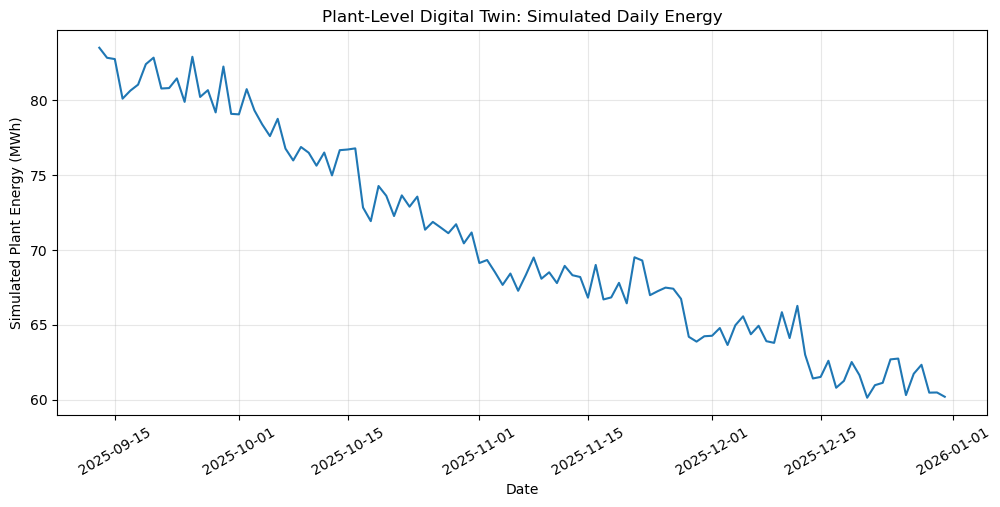

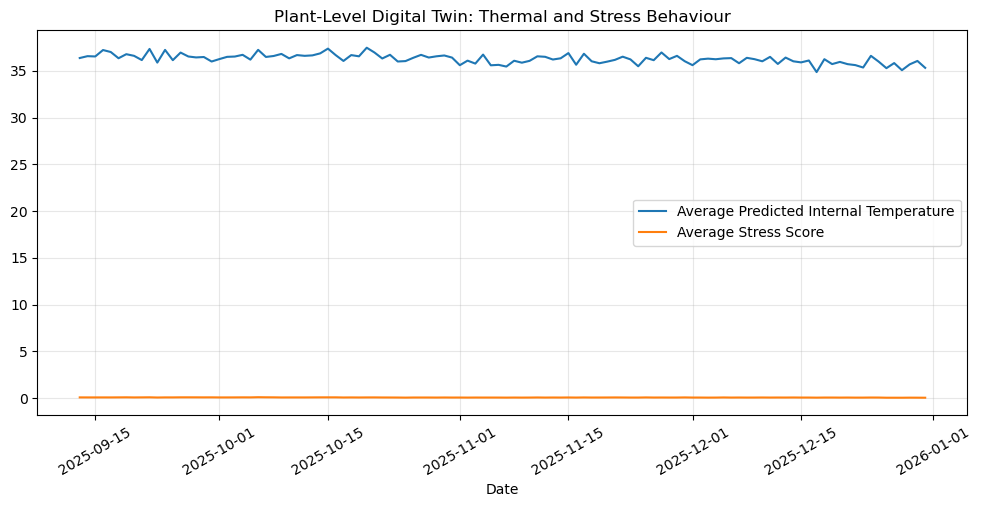

In [11]:
# ============================================
# 13. Plant-level simulation visuals
# ============================================

plt.figure(figsize=(12, 5))
plt.plot(plant_daily_simulation["date"], plant_daily_simulation["simulated_energy_mwh"])
plt.xlabel("Date")
plt.ylabel("Simulated Plant Energy (MWh)")
plt.title("Plant-Level Digital Twin: Simulated Daily Energy")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(plant_daily_simulation["date"], plant_daily_simulation["avg_predicted_temperature_c"], label="Average Predicted Internal Temperature")
plt.plot(plant_daily_simulation["date"], plant_daily_simulation["avg_stress_score"], label="Average Stress Score")
plt.xlabel("Date")
plt.title("Plant-Level Digital Twin: Thermal and Stress Behaviour")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=30)
plt.legend()
plt.show()

## 14. What-if Scenario Simulator

The simulator changes **external and controllable variables**, then passes the changed state through the trained digital twin.

| Scenario | Description |
|---|---|
| `baseline` | Original observed operating state. |
| `heatwave` | Higher ambient temperature and UV exposure. |
| `dust_soiling_event` | Higher dust/soiling and slightly reduced maintenance quality. |
| `power_quality_disturbance` | More errors, overloads, and thermal cycling. |
| `preventive_maintenance` | Lower dust, fewer errors/restarts, and improved maintenance quality. |
| `combined_stress` | Heatwave + soiling + power-quality disturbance. |

In [12]:
# ============================================
# 15. Scenario simulation functions
# ============================================


def apply_scenario(data: pd.DataFrame, scenario_name: str) -> pd.DataFrame:
    scenario = data.copy()

    if scenario_name == "baseline":
        pass
    elif scenario_name == "heatwave":
        scenario["ambient_temperature_c"] = scenario["ambient_temperature_c"] + 8
        scenario["uv_exposure_index"] = (scenario["uv_exposure_index"] + 1.5).clip(0, 10)
        scenario["humidity_pct"] = (scenario["humidity_pct"] - 5).clip(10, 100)
        scenario["thermal_cycling_count_today"] = scenario["thermal_cycling_count_today"] + 1
    elif scenario_name == "dust_soiling_event":
        scenario["dust_soiling_index"] = (scenario["dust_soiling_index"] + 0.25).clip(0, 1)
        scenario["maintenance_quality_score"] = (scenario["maintenance_quality_score"] - 0.04).clip(0, 1)
    elif scenario_name == "power_quality_disturbance":
        scenario["error_code_count_today"] = scenario["error_code_count_today"] + 2
        scenario["overload_events_today"] = scenario["overload_events_today"] + 1
        scenario["thermal_cycling_count_today"] = scenario["thermal_cycling_count_today"] + 1
    elif scenario_name == "preventive_maintenance":
        scenario["dust_soiling_index"] = (scenario["dust_soiling_index"] - 0.20).clip(0, 1)
        scenario["maintenance_quality_score"] = (scenario["maintenance_quality_score"] + 0.08).clip(0, 1)
        scenario["restart_count_today"] = (scenario["restart_count_today"] - 1).clip(0)
        scenario["error_code_count_today"] = (scenario["error_code_count_today"] - 1).clip(0)
        scenario["overload_events_today"] = (scenario["overload_events_today"] - 1).clip(0)
    elif scenario_name == "combined_stress":
        scenario = apply_scenario(scenario, "heatwave")
        scenario = apply_scenario(scenario, "dust_soiling_event")
        scenario = apply_scenario(scenario, "power_quality_disturbance")
    else:
        raise ValueError(f"Unknown scenario: {scenario_name}")

    scenario["event_pressure_score"] = (
        scenario["restart_count_today"]
        + scenario["error_code_count_today"]
        + 1.5 * scenario["overload_events_today"]
        + 0.5 * scenario["thermal_cycling_count_today"]
    )
    return scenario


def run_component_simulation(raw_data: pd.DataFrame, scenario_name: str) -> pd.DataFrame:
    feature_data = add_digital_twin_features(raw_data)
    feature_data = feature_data.dropna(subset=["efficiency_pct_lag1", "internal_temperature_c_lag1"]).reset_index(drop=True)
    scenario_features = apply_scenario(feature_data, scenario_name)

    X_scenario = scenario_features[FEATURE_COLUMNS]
    preds = component_twin_model.predict(X_scenario)

    output = scenario_features[[
        "date", "inverter_id", "manufacturer", "climate_zone", "rated_capacity_kw",
        "operating_hours_today", "dust_soiling_index", "ambient_temperature_c",
        "restart_count_today", "error_code_count_today", "overload_events_today", "thermal_cycling_count_today",
        "maintenance_quality_score"
    ]].copy()

    for i, target in enumerate(TARGET_COLUMNS):
        output[f"predicted_{target}"] = preds[:, i]

    output = add_simulated_energy_and_risk(output)
    output["scenario"] = scenario_name
    return output


def summarise_plant_scenario(component_scenario_output: pd.DataFrame) -> pd.DataFrame:
    summary = (
        component_scenario_output.groupby("scenario")
        .agg(
            records=("inverter_id", "count"),
            unique_assets=("inverter_id", "nunique"),
            total_simulated_energy_mwh=("simulated_energy_mwh", "sum"),
            avg_simulated_energy_mwh=("simulated_energy_mwh", "mean"),
            avg_predicted_efficiency_pct=("predicted_efficiency_pct", "mean"),
            avg_predicted_temperature_c=("predicted_internal_temperature_c", "mean"),
            avg_voltage_ripple=("predicted_voltage_ripple", "mean"),
            avg_harmonic_distortion_pct=("predicted_current_harmonic_distortion_pct", "mean"),
            avg_insulation_resistance_mohm=("predicted_insulation_resistance_mohm", "mean"),
            avg_stress_score=("digital_twin_stress_score", "mean"),
            high_risk_records=("digital_twin_stress_score", lambda x: int((x >= 0.5).sum())),
            critical_records=("digital_twin_stress_score", lambda x: int((x >= 0.75).sum())),
        )
        .reset_index()
    )
    return summary

In [ ]:
# ============================================
# 16. Run scenarios on the most recent 30-day window
# ============================================

max_date = df["date"].max()
window_start = max_date - pd.Timedelta(days=30)
scenario_input = df[df["date"] >= window_start].copy()

scenario_names = [
    "baseline",
    "heatwave",
    "dust_soiling_event",
    "power_quality_disturbance",
    "preventive_maintenance",
    "combined_stress",
]

scenario_outputs = []
for name in scenario_names:
    scenario_outputs.append(run_component_simulation(scenario_input, name))

scenario_component_df = pd.concat(scenario_outputs, ignore_index=True)
scenario_summary_df = summarise_plant_scenario(scenario_component_df)

baseline_energy = scenario_summary_df.loc[
    scenario_summary_df["scenario"] == "baseline", "total_simulated_energy_mwh"
].iloc[0]
baseline_stress = scenario_summary_df.loc[
    scenario_summary_df["scenario"] == "baseline", "avg_stress_score"
].iloc[0]

scenario_summary_df["energy_change_vs_baseline_mwh"] = scenario_summary_df["total_simulated_energy_mwh"] - baseline_energy
scenario_summary_df["energy_change_vs_baseline_%"] = scenario_summary_df["energy_change_vs_baseline_mwh"] / baseline_energy * 100
scenario_summary_df["stress_change_vs_baseline"] = scenario_summary_df["avg_stress_score"] - baseline_stress

scenario_component_df.to_csv(OUTPUT_DIR / "scenario_component_outputs.csv", index=False)
scenario_summary_df.to_csv(OUTPUT_DIR / "scenario_summary_outputs.csv", index=False)

display(scenario_summary_df)

In [ ]:
# ============================================
# 17. Scenario comparison plots
# ============================================

plot_summary = scenario_summary_df.set_index("scenario").loc[scenario_names].reset_index()

plt.figure(figsize=(10, 5))
plt.bar(plot_summary["scenario"], plot_summary["energy_change_vs_baseline_%"])
plt.ylabel("Energy Change vs Baseline (%)")
plt.title("Digital Twin What-if Simulation: Energy Impact by Scenario")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(plot_summary["scenario"], plot_summary["avg_predicted_temperature_c"])
plt.ylabel("Average Predicted Internal Temperature (°C)")
plt.title("Digital Twin What-if Simulation: Thermal Impact by Scenario")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(plot_summary["scenario"], plot_summary["high_risk_records"])
plt.ylabel("High-Risk Component Records")
plt.title("Digital Twin What-if Simulation: High-Risk Records by Scenario")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 18. Scenario Interpretation Helper

This section converts simulation outputs into simple operational insights. In a production dashboard, this would appear as an operator-facing recommendation panel.

In [ ]:
# ============================================
# 19. Generate operational interpretation
# ============================================


def interpret_scenario(row):
    scenario = row["scenario"]
    energy_change = row["energy_change_vs_baseline_%"]
    stress_change = row["stress_change_vs_baseline"]
    high_risk = row["high_risk_records"]
    critical = row["critical_records"]

    if scenario == "baseline":
        return "Baseline operating state used for comparison."
    if energy_change < -5 and stress_change > 0.05:
        return f"Material energy loss and higher stress detected. Review affected assets before this scenario occurs. High-risk records: {high_risk}, critical records: {critical}."
    if energy_change < -2:
        return f"Moderate energy loss expected. Monitor production and inspect assets with elevated stress. High-risk records: {high_risk}."
    if stress_change > 0.05:
        return f"Stress increases even if energy impact is limited. Prioritise thermal and power-quality checks. High-risk records: {high_risk}."
    if energy_change > 1:
        return "Scenario improves simulated output or reduces operational constraints. This may represent a beneficial maintenance action."
    return "Minor simulated impact. Continue monitoring."

scenario_summary_df["operator_interpretation"] = scenario_summary_df.apply(interpret_scenario, axis=1)
display(scenario_summary_df[[
    "scenario", "energy_change_vs_baseline_%", "avg_stress_score", "high_risk_records", "critical_records", "operator_interpretation"
]])

## 20. Synthetic Failure Injection

A useful digital twin should support controlled failure injection. Here, simulated records are classified into fault categories based on predicted behaviour and stress thresholds.

This is a prototype mechanism for scenario testing and future RL-agent training. It is not a substitute for real labelled fault data.

In [ ]:
# ============================================
# 21. Fault injection and component-level risk table
# ============================================


def assign_injected_fault_type(row):
    if row["predicted_internal_temperature_c"] >= 52 or row["thermal_cycling_count_today"] >= 8:
        return "THERMAL_STRESS_INJECTION"
    if row["predicted_voltage_ripple"] >= 4.2 or row["predicted_current_harmonic_distortion_pct"] >= 8.0:
        return "POWER_QUALITY_INJECTION"
    if row["predicted_insulation_resistance_mohm"] <= 70:
        return "INSULATION_DEGRADATION_INJECTION"
    if row["error_code_count_today"] >= 4 or row["restart_count_today"] >= 4:
        return "CONTROL_OR_COMMUNICATION_INJECTION"
    if row["digital_twin_stress_score"] >= 0.5:
        return "GENERAL_HIGH_STRESS_INJECTION"
    return "NO_INJECTED_FAULT"

scenario_component_df["injected_fault_type"] = scenario_component_df.apply(assign_injected_fault_type, axis=1)

fault_injection_summary = (
    scenario_component_df.groupby(["scenario", "injected_fault_type"])
    .size()
    .reset_index(name="record_count")
    .sort_values(["scenario", "record_count"], ascending=[True, False])
)

fault_injection_summary.to_csv(OUTPUT_DIR / "fault_injection_summary.csv", index=False)
display(fault_injection_summary)

top_risky_assets = (
    scenario_component_df[scenario_component_df["scenario"] == "combined_stress"]
    .sort_values("digital_twin_stress_score", ascending=False)
    .head(20)
    [[
        "date", "inverter_id", "manufacturer", "climate_zone", "predicted_efficiency_pct",
        "predicted_internal_temperature_c", "predicted_voltage_ripple",
        "predicted_current_harmonic_distortion_pct", "predicted_insulation_resistance_mohm",
        "simulated_energy_mwh", "digital_twin_stress_score", "simulated_fault_class", "injected_fault_type"
    ]]
)

display(top_risky_assets)

## 22. Explainability Snapshot

For production, Digital Twin predictions should be explainable. Because the prototype uses an interpretable decision tree, we can directly extract feature importances from the trained model.

This provides a quick operator-facing view of which asset, environmental, operating, and lagged-state variables most influence simulated behaviour.

In [ ]:
# ============================================
# 23. Explainability: feature importance from the digital twin
# ============================================

# Get transformed feature names after preprocessing.
transformed_feature_names = component_twin_model.named_steps["preprocessor"].get_feature_names_out()
feature_importances = component_twin_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "transformed_feature": transformed_feature_names,
    "importance": feature_importances,
}).sort_values("importance", ascending=False)

importance_df.to_csv(OUTPUT_DIR / "digital_twin_feature_importance.csv", index=False)
display(importance_df.head(20))

plt.figure(figsize=(10, 6))
top_imp = importance_df.head(15).sort_values("importance")
plt.barh(top_imp["transformed_feature"], top_imp["importance"])
plt.xlabel("Decision Tree Feature Importance")
plt.title("Explainability Snapshot: Key Drivers of Digital Twin Simulation")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

## 24. Single-Asset Digital Twin API Prototype

This helper demonstrates how the trained twin could be wrapped behind an API endpoint. It accepts an inverter ID, applies a scenario, and returns a JSON-like simulation result.

In [ ]:
# ============================================
# 25. Single-asset inference helper
# ============================================


def run_single_asset_twin(inverter_id: str, scenario_name: str = "baseline", as_of_date=None):
    asset_history = df[df["inverter_id"] == inverter_id].copy()
    if asset_history.empty:
        raise ValueError(f"No records found for inverter_id={inverter_id}")

    if as_of_date is not None:
        as_of_date = pd.to_datetime(as_of_date)
        asset_history = asset_history[asset_history["date"] <= as_of_date]
        if asset_history.empty:
            raise ValueError("No records available on or before as_of_date.")

    # Use recent history so lag features can be calculated.
    recent_history = asset_history.tail(40).copy()
    result = run_component_simulation(recent_history, scenario_name)
    latest = result.sort_values("date").iloc[-1]

    response = {
        "inverter_id": latest["inverter_id"],
        "simulation_date": str(pd.to_datetime(latest["date"]).date()),
        "scenario": scenario_name,
        "predicted_efficiency_pct": round(float(latest["predicted_efficiency_pct"]), 3),
        "predicted_internal_temperature_c": round(float(latest["predicted_internal_temperature_c"]), 3),
        "predicted_voltage_ripple": round(float(latest["predicted_voltage_ripple"]), 3),
        "predicted_reactive_power_capability": round(float(latest["predicted_reactive_power_capability"]), 3),
        "predicted_harmonic_distortion_pct": round(float(latest["predicted_current_harmonic_distortion_pct"]), 3),
        "predicted_insulation_resistance_mohm": round(float(latest["predicted_insulation_resistance_mohm"]), 3),
        "simulated_energy_mwh": round(float(latest["simulated_energy_mwh"]), 4),
        "digital_twin_stress_score": round(float(latest["digital_twin_stress_score"]), 3),
        "simulated_fault_class": latest["simulated_fault_class"],
    }
    return response

example_asset_id = df["inverter_id"].iloc[0]
print(json.dumps(run_single_asset_twin(example_asset_id, "baseline"), indent=2))
print(json.dumps(run_single_asset_twin(example_asset_id, "combined_stress"), indent=2))

## 26. Export Prototype Artifacts

The following files are saved in the `digital_twin_outputs` folder:

| File | Description |
|---|---|
| `component_twin_model.joblib` | Trained multi-output component-level digital twin model. |
| `component_twin_metrics.csv` | MAE, RMSE, MAPE, R², and within-3%-accuracy metrics. |
| `component_level_predictions.csv` | Actual vs predicted outputs for the test period. |
| `plant_daily_simulation_base.csv` | Plant-level baseline simulation output by date. |
| `scenario_component_outputs.csv` | Component-level what-if scenario predictions. |
| `scenario_summary_outputs.csv` | Plant-level what-if scenario comparison. |
| `fault_injection_summary.csv` | Synthetic failure injection counts by scenario. |
| `digital_twin_feature_importance.csv` | Decision-tree feature importance output. |

In [ ]:
# ============================================
# 27. Save model and metadata
# ============================================

model_path = OUTPUT_DIR / "component_twin_model.joblib"
joblib.dump(component_twin_model, model_path)

metadata = {
    "project": "Omni-Grid Digital Twin & Simulation Engine",
    "prototype_version": "1.0.0",
    "dataset_file": DATASET_FILE,
    "rows_used": int(len(model_df)),
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "date_min": str(model_df["date"].min().date()),
    "date_max": str(model_df["date"].max().date()),
    "targets": TARGET_COLUMNS,
    "features": FEATURE_COLUMNS,
    "scenario_names": scenario_names,
    "model_type": "DecisionTreeRegressor with physics-inspired digital-twin features",
}

with open(OUTPUT_DIR / "prototype_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model to:", model_path)
print("Saved metadata to:", OUTPUT_DIR / "prototype_metadata.json")
print("All prototype outputs are in:", OUTPUT_DIR)

## 28. Prototype Summary

This notebook creates a working Digital Twin & Simulation Engine prototype for the Omni-Grid platform.

### What the prototype does

- Builds a **component-level digital twin** for inverter electrical and thermal behaviour.
- Evaluates the twin against observed synthetic telemetry using regression and 3%-tolerance metrics.
- Converts component predictions into **plant-level simulated energy and risk KPIs**.
- Runs realistic **what-if scenarios** such as heatwave, soiling, power-quality disturbance, preventive maintenance, and combined stress.
- Supports **synthetic failure injection** for thermal, power-quality, insulation, and control-related stress patterns.
- Exports trained model artifacts, metrics, predictions, and simulation summaries.

### How this can be extended

1. Replace synthetic data with real SCADA/IoT inverter telemetry.
2. Add stronger physics models for PV/inverter thermal and electrical behaviour.
3. Connect simulation outputs to the Automated Remote Fixing and RL training environment.
4. Add scenario libraries for weather, grid events, maintenance plans, and dispatch strategies.
5. Deploy the model behind an API and dashboard for operator-facing digital twin simulation.